What are the most demanded skills for the top 3 most popular data roles?
Plan
Clean-up skill column
Calculate skill count based on job_title_short
Calculate skill percentage
Plot final findings

In [24]:
# Importing Libraries
import ast
import pandas as pd
import seaborn as sns
from datasets import load_dataset
import matplotlib.pyplot as plt  

# Loading Data
dataset = load_dataset('lukebarousse/data_jobs')
df = dataset['train'].to_pandas()

# Data Cleanup
df['job_posted_date'] = pd.to_datetime(df['job_posted_date'])
df['job_skills'] = df['job_skills'].apply(lambda x: ast.literal_eval(x) if pd.notna(x) else x)

In [25]:
#Filter Data for the United States
df_US = df[df['job_country']== 'United States']

In [26]:
df_skills=df_US.explode('job_skills')
df_skills[['job_title','job_skills']]


,job_title,job_skills
0,Senior Clinical Data Engineer / Principal Clin...,NaN
3,LEAD ENGINEER - PRINCIPAL ANALYST - PRINCIPAL ...,python
3,LEAD ENGINEER - PRINCIPAL ANALYST - PRINCIPAL ...,c++
3,LEAD ENGINEER - PRINCIPAL ANALYST - PRINCIPAL ...,java
3,LEAD ENGINEER - PRINCIPAL ANALYST - PRINCIPAL ...,matlab
...,...,...
785692,Data Scientist- Hybrid Work Location,r
785703,Data Analyst - CRYPTOGRAPHY - Full-time,NaN
785705,Expert Business Data Analyst - Now Hiring,sql
785705,Expert Business Data Analyst - Now Hiring,python


Count Skills per Job Title

In [27]:
# Group by job_skills and job_title_short and count the number of occurrences
df_skills_count = df_skills.groupby(['job_skills','job_title_short']).size()
# Name the count column as count
df_skills_count=df_skills_count.reset_index(name ='skill_count')
# Sort the values by skill_count in descending order
df_skills_count= df_skills_count.sort_values(by='skill_count', ascending = False)
df_skills_count

,job_skills,job_title_short,skill_count
1209,python,Data Scientist,42379
1521,sql,Data Analyst,34452
1523,sql,Data Scientist,30034
455,excel,Data Analyst,27519
1243,r,Data Scientist,26022
...,...,...,...
1785,vue.js,Business Analyst,1
60,arch,Business Analyst,1
71,asana,Machine Learning Engineer,1
968,no-sql,Machine Learning Engineer,1


Create List of Top 3 Roles

In [34]:
job_titles=df_skills_count['job_title_short'].unique().tolist()
job_titles = sorted(job_titles[:3])
job_titles

['Data Analyst', 'Data Engineer', 'Data Scientist']

Plot Skill Counts
Creates a stacked horizontal bar chart for the top 5 skills for Top 3 roles, displaying the frequency of each skill.

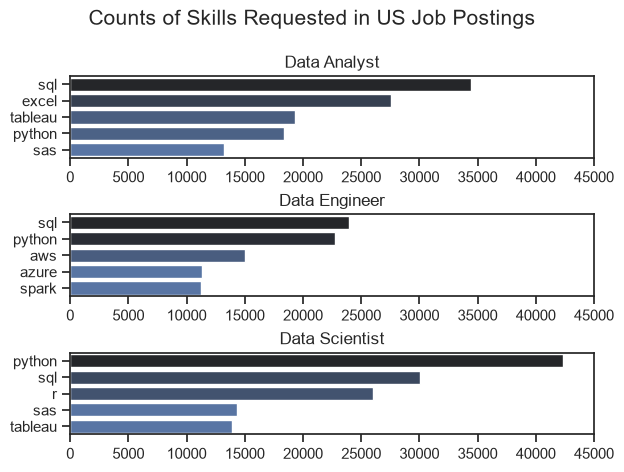

In [36]:
fig , ax = plt.subplots(len(job_titles), 1)
sns.set_theme(style ='ticks')
for i , job_title in enumerate(job_titles):
    df_plot =df_skills_count[ df_skills_count['job_title_short'] == job_title].head(5)[::-1]
    sns.barplot(df_plot , x = 'skill_count' , y= 'job_skills' , hue = 'skill_count',ax =ax[i] , palette = 'dark:b_r', legend=False)
    ax[i].invert_yaxis()
    ax[i].set_title(job_title)
    ax[i].set_ylabel('')
    ax[i].set_xlabel('')
    ax[i].set_xlim(0, 45000) # make the scales the same

fig.suptitle('Counts of Skills Requested in US Job Postings', fontsize=15)
fig.tight_layout(h_pad=0.5) # fix the overlap
plt.show()



Convert Counts to Percentages

In [30]:
# Using original df to get the count of job titles
df_job_title_count = df_US['job_title_short'].value_counts().reset_index(name = 'jobs_total')
df_job_title_count 

,job_title_short,jobs_total
0,Data Analyst,67816
1,Data Scientist,58830
2,Data Engineer,35080
3,Senior Data Scientist,12946
4,Senior Data Analyst,11791
5,Senior Data Engineer,9289
6,Business Analyst,7382
7,Software Engineer,1814
8,Machine Learning Engineer,921
9,Cloud Engineer,423


In [31]:
#merge df_skills_count and df_job_title_count, based on the 'job_title_short' column
df_skills_perc =pd.merge(df_skills_count, df_job_title_count, how ='left', on ='job_title_short')
df_skills_perc['skill_percent'] = (df_skills_perc['skill_count']/df_skills_perc['jobs_total'])*100
df_skills_perc

,job_skills,job_title_short,skill_count,jobs_total,skill_percent
0,python,Data Scientist,42379,58830,72.036376
1,sql,Data Analyst,34452,67816,50.802171
2,sql,Data Scientist,30034,58830,51.052184
3,excel,Data Analyst,27519,67816,40.578919
4,r,Data Scientist,26022,58830,44.232534
...,...,...,...,...,...
1865,vue.js,Business Analyst,1,7382,0.013546
1866,arch,Business Analyst,1,7382,0.013546
1867,asana,Machine Learning Engineer,1,921,0.108578
1868,no-sql,Machine Learning Engineer,1,921,0.108578


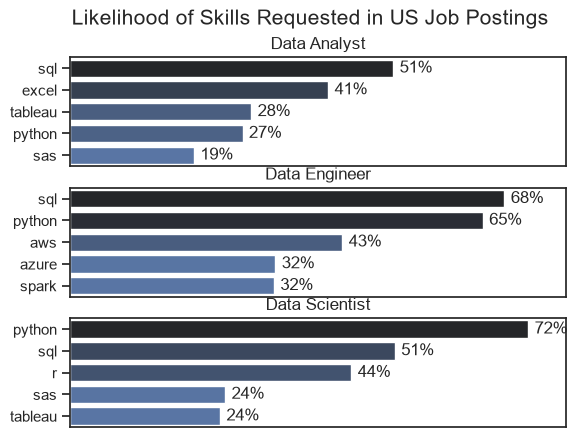

In [37]:
fig , ax = plt.subplots(len(job_titles), 1)
sns.set_theme(style ='ticks')
for i , job_title in enumerate(job_titles):
    df_plot =df_skills_perc[ df_skills_perc['job_title_short'] == job_title].head(5)
    sns.barplot(df_plot , x= 'skill_percent' , y='job_skills' , hue='skill_percent',ax=ax[i] , palette='dark:b_r', legend=False)
    ax[i].set_title(job_title)
    ax[i].set_ylabel('')
    ax[i].set_xlabel('')
    ax[i].set_xlim(0, 78) # make the scales the same
 # remove the x-axis tick labels for better readability
    if i != len(job_title) - 1:
        ax[i].set_xticks([])
 # Add the percentage at the end of each bar
    for n, v in enumerate(df_plot['skill_percent']):
     ax[i].text(v + 1, n, f'{v:.0f}%', va='center')
      
fig.suptitle('Likelihood of Skills Requested in US Job Postings', fontsize=15)
plt.show()

